# 01 - Exploratory data analysis (real data)

Public insurance claims dataset (Derrick Mwiti): 1,000 automobile claims, 39 columns, target `fraud_reported`. This notebook is **descriptive**: nothing computed here is used to fit a model (imputation, encoding and scaling are learned inside the training pipelines, on training folds only).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.max_columns', 50, 'display.width', 200, 'display.precision', 3)
FIG = ROOT / 'results' / 'figures'
MET = ROOT / 'results' / 'metrics'

In [2]:
from src import config, data
from src.features import ClaimFeatureBuilder
df = data.load_clean(ROOT / 'data' / 'insurance_claims.csv')
print(df.shape)
df.head()

umbrella_limit: 1 negative value(s) set to NaN


(1000, 39)


,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductible,policy_annual_premium,umbrella_limit,insured_zip,insured_sex,insured_education_level,insured_occupation,insured_hobbies,insured_relationship,capital_gains,capital_loss,incident_date,incident_type,collision_type,incident_severity,authorities_contacted,incident_state,incident_city,incident_location,incident_hour,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,is_fraud
0,328.0,48.0,521585,2014-10-17,OH,250/500,1000.0,1406.91,0.000e+00,466132,MALE,MD,craft-repair,sleeping,husband,53300.0,0.0,2015-01-25,Single Vehicle Collision,Side Collision,Major Damage,Police,SC,Columbus,9935 4th Drive,5.0,1.0,YES,1.0,2.0,YES,71610.0,6510.0,13020.0,52080.0,Saab,92x,2004.0,1
1,228.0,42.0,342868,2006-06-27,IN,250/500,2000.0,1197.22,5.000e+06,468176,MALE,MD,machine-op-inspct,reading,other-relative,0.0,0.0,2015-01-21,Vehicle Theft,UNKNOWN,Minor Damage,Police,VA,Riverwood,6608 MLK Hwy,8.0,1.0,UNKNOWN,0.0,0.0,UNKNOWN,5070.0,780.0,780.0,3510.0,Mercedes,E400,2007.0,1
2,134.0,29.0,687698,2000-09-06,OH,100/300,2000.0,1413.14,5.000e+06,430632,FEMALE,PhD,sales,board-games,own-child,35100.0,0.0,2015-02-22,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NY,Columbus,7121 Francis Lane,7.0,3.0,NO,2.0,3.0,NO,34650.0,7700.0,3850.0,23100.0,Dodge,RAM,2007.0,0
3,256.0,41.0,227811,1990-05-25,IL,250/500,2000.0,1415.74,6.000e+06,608117,FEMALE,PhD,armed-forces,board-games,unmarried,48900.0,-62400.0,2015-01-10,Single Vehicle Collision,Front Collision,Major Damage,Police,OH,Arlington,6956 Maple Drive,5.0,1.0,UNKNOWN,1.0,2.0,NO,63400.0,6340.0,6340.0,50720.0,Chevrolet,Tahoe,2014.0,1
4,228.0,44.0,367455,2014-06-06,IL,500/1000,1000.0,1583.91,6.000e+06,610706,MALE,Associate,sales,board-games,unmarried,66000.0,-46000.0,2015-02-17,Vehicle Theft,UNKNOWN,Minor Damage,None,NY,Arlington,3041 3rd Ave,20.0,1.0,NO,0.0,1.0,NO,6500.0,1300.0,650.0,4550.0,Accura,RSX,2009.0,0


## Data quality

* `?` markers appear in three categorical columns. They are kept as an explicit `UNKNOWN` level: for `collision_type`, `UNKNOWN` corresponds exactly to the vehicle thefts and parked-car incidents (structural missingness).
* The literal string `"None"` of `authorities_contacted` is a real level; reading the CSV with pandas defaults would silently turn it into NaN.
* One negative `umbrella_limit` is treated as an entry error (set to NaN, imputed in the pipeline).

In [3]:
summary = json.loads((MET / 'eda_summary.json').read_text())
{k: v for k, v in summary.items() if k != 'univariate_roc_auc_claim_amounts'}

{'n_rows': 1000,
 'n_source_columns': 39,
 'fraud_rate': 0.247,
 'n_fraud': 247,
 'duplicated_rows': 0,
 'unknown_category_counts': {'collision_type': 178,
  'property_damage': 360,
  'police_report_available': 343},
 'numeric_nan_counts': {'umbrella_limit': 1},
 'iqr_outlier_counts': {'age': 4,
  'policy_annual_premium': 9,
  'umbrella_limit': 201,
  'property_claim': 6,
  'total_claim_amount': 1},
 'total_claim_equals_sum_of_components': True,
 'incident_date_range': ['2015-01-01', '2015-03-01']}

In [4]:
pd.crosstab(df.incident_type, df.collision_type)

collision_type,Front Collision,Rear Collision,Side Collision,UNKNOWN
incident_type,,,,
Multi-vehicle Collision,115,152,152,0
Parked Car,0,0,0,84
Single Vehicle Collision,139,140,124,0
Vehicle Theft,0,0,0,94


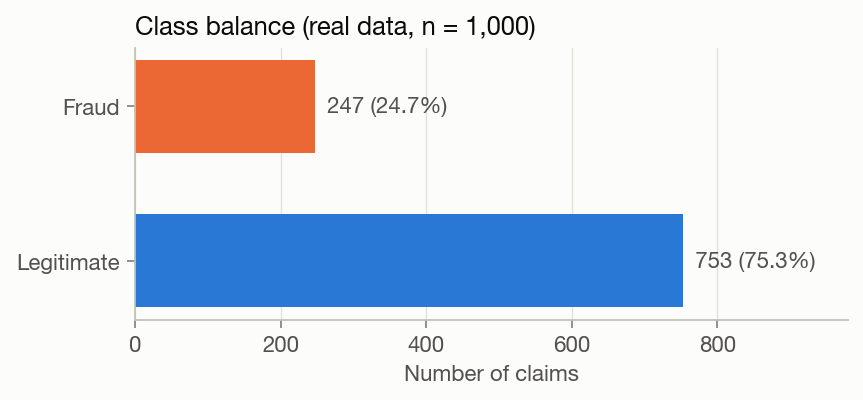

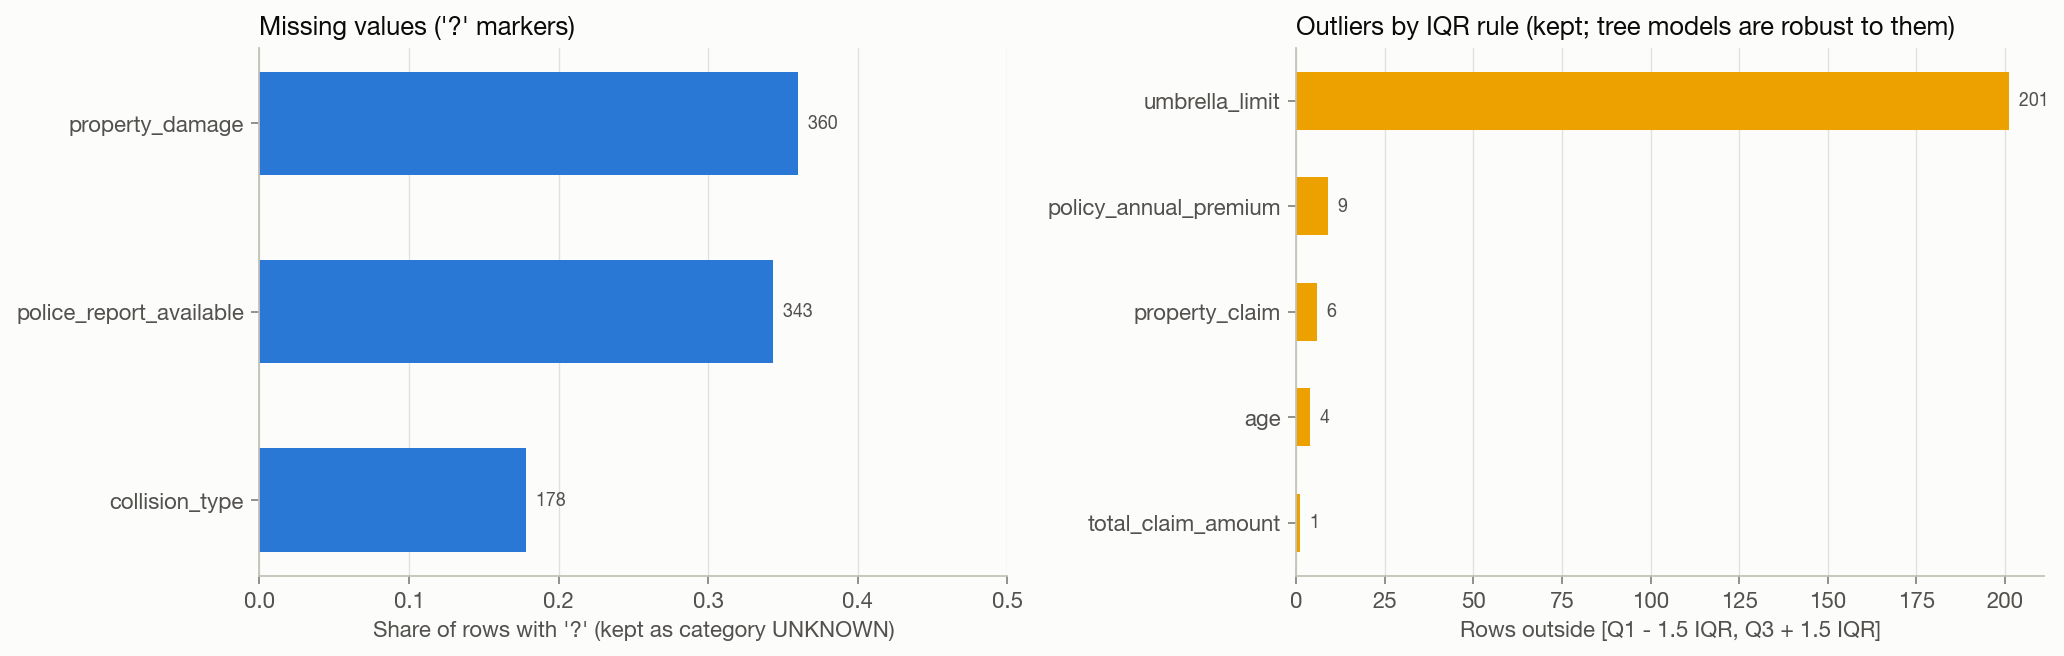

In [5]:
display(Image(FIG / 'eda_class_balance.png'))
display(Image(FIG / 'eda_data_quality.png'))

## Leakage audit of the claim amounts

`total_claim_amount` is exactly `injury_claim + property_claim + vehicle_claim` on every row, so keeping it adds a perfectly collinear column and no information: it is dropped. The amounts are *claimed* amounts, known when the claim is filed (fraudulent claims are not recorded with a zero payout), so they are not target leakage by construction. Empirically their univariate ROC-AUC is modest (below), far from the near-perfect separation a leaked post-investigation variable would give. The training stage also runs an ablation with and without every amount feature.

In [6]:
from sklearn.metrics import roc_auc_score
print('max |total - sum of components| =', (df.total_claim_amount - df[config.CLAIM_COMPONENTS].sum(axis=1)).abs().max())
pd.Series(summary['univariate_roc_auc_claim_amounts'], name='univariate ROC-AUC')

max |total - sum of components| = 0.0


total_claim_amount    0.593
injury_claim          0.559
property_claim        0.589
vehicle_claim         0.596
Name: univariate ROC-AUC, dtype: float64

## Distributions and fraud rates

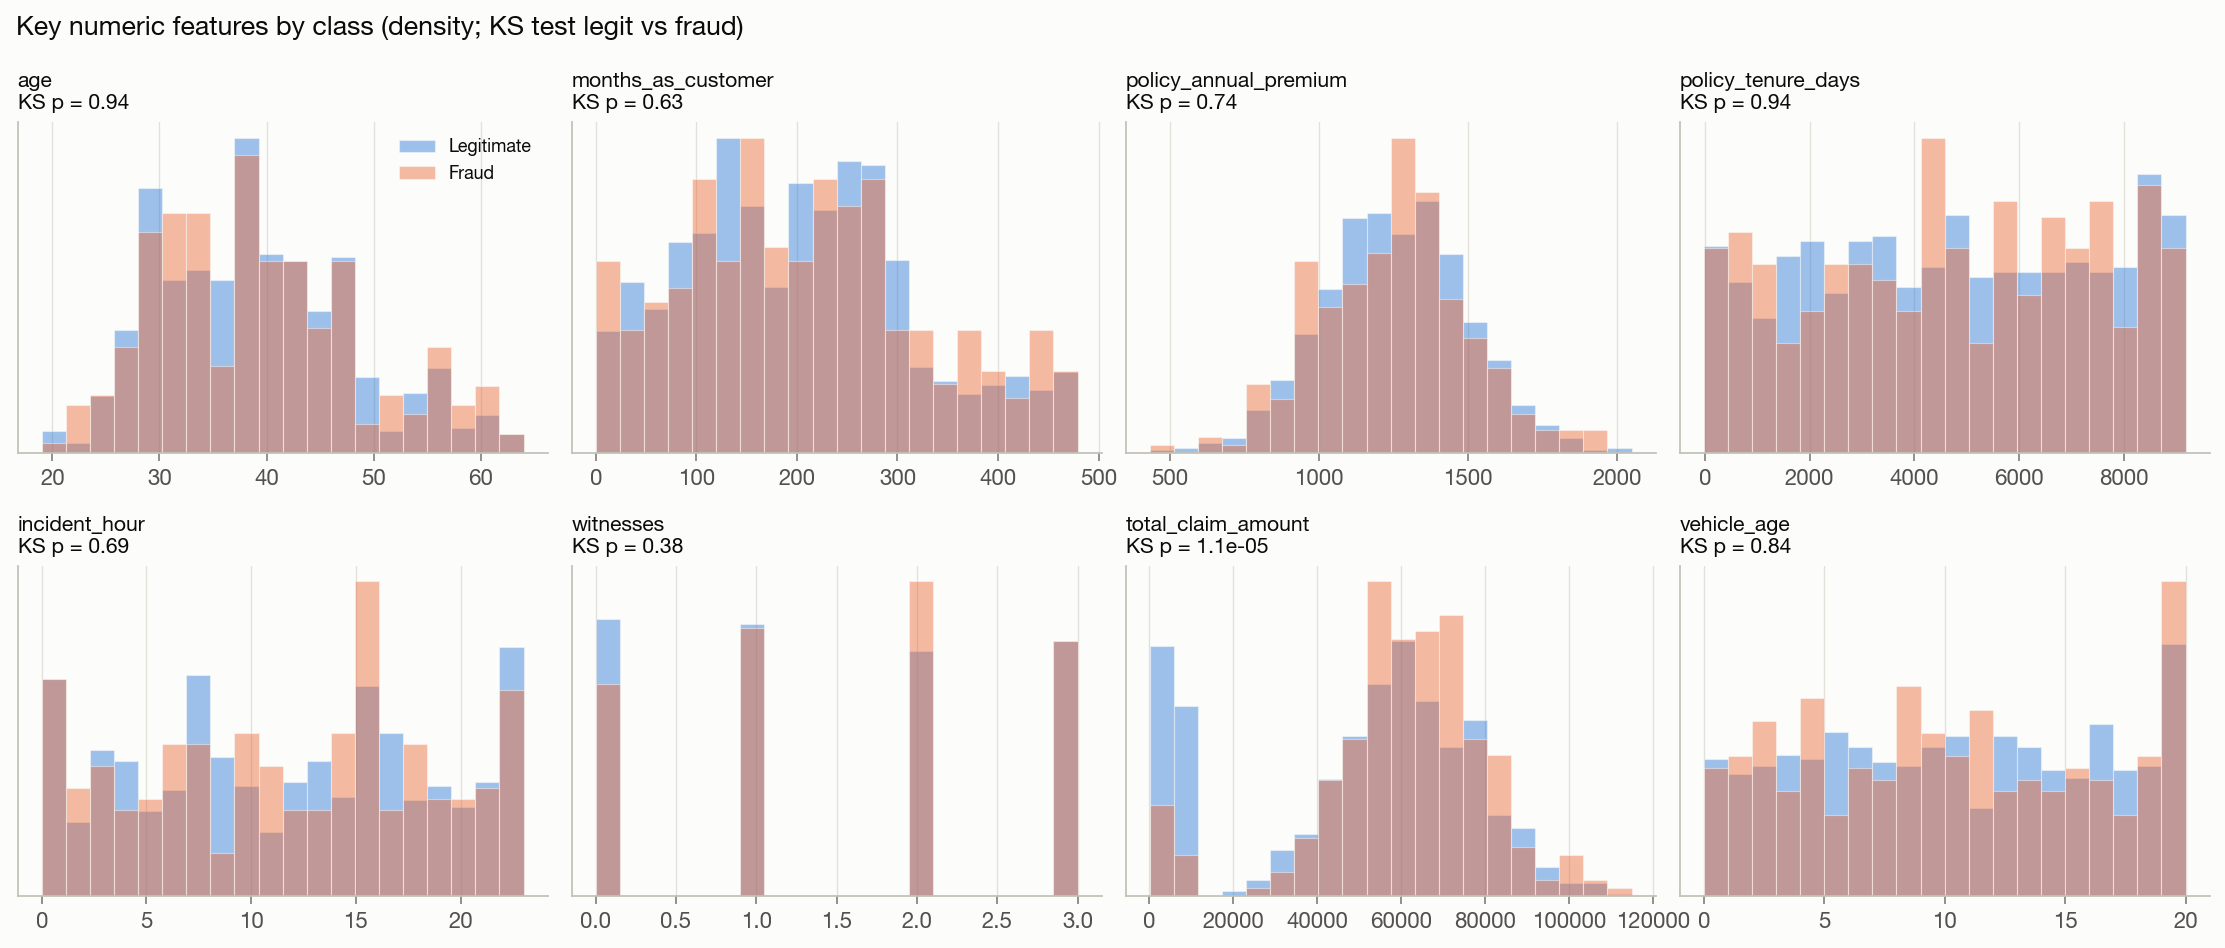

In [7]:
display(Image(FIG / 'eda_numeric_distributions.png'))

Most numeric variables have nearly identical distributions in both classes (KS p-values well above 0.05). The total claim amount is the exception: the low-amount mode (< $15k) is almost entirely legitimate - these are the thefts and parked-car incidents.

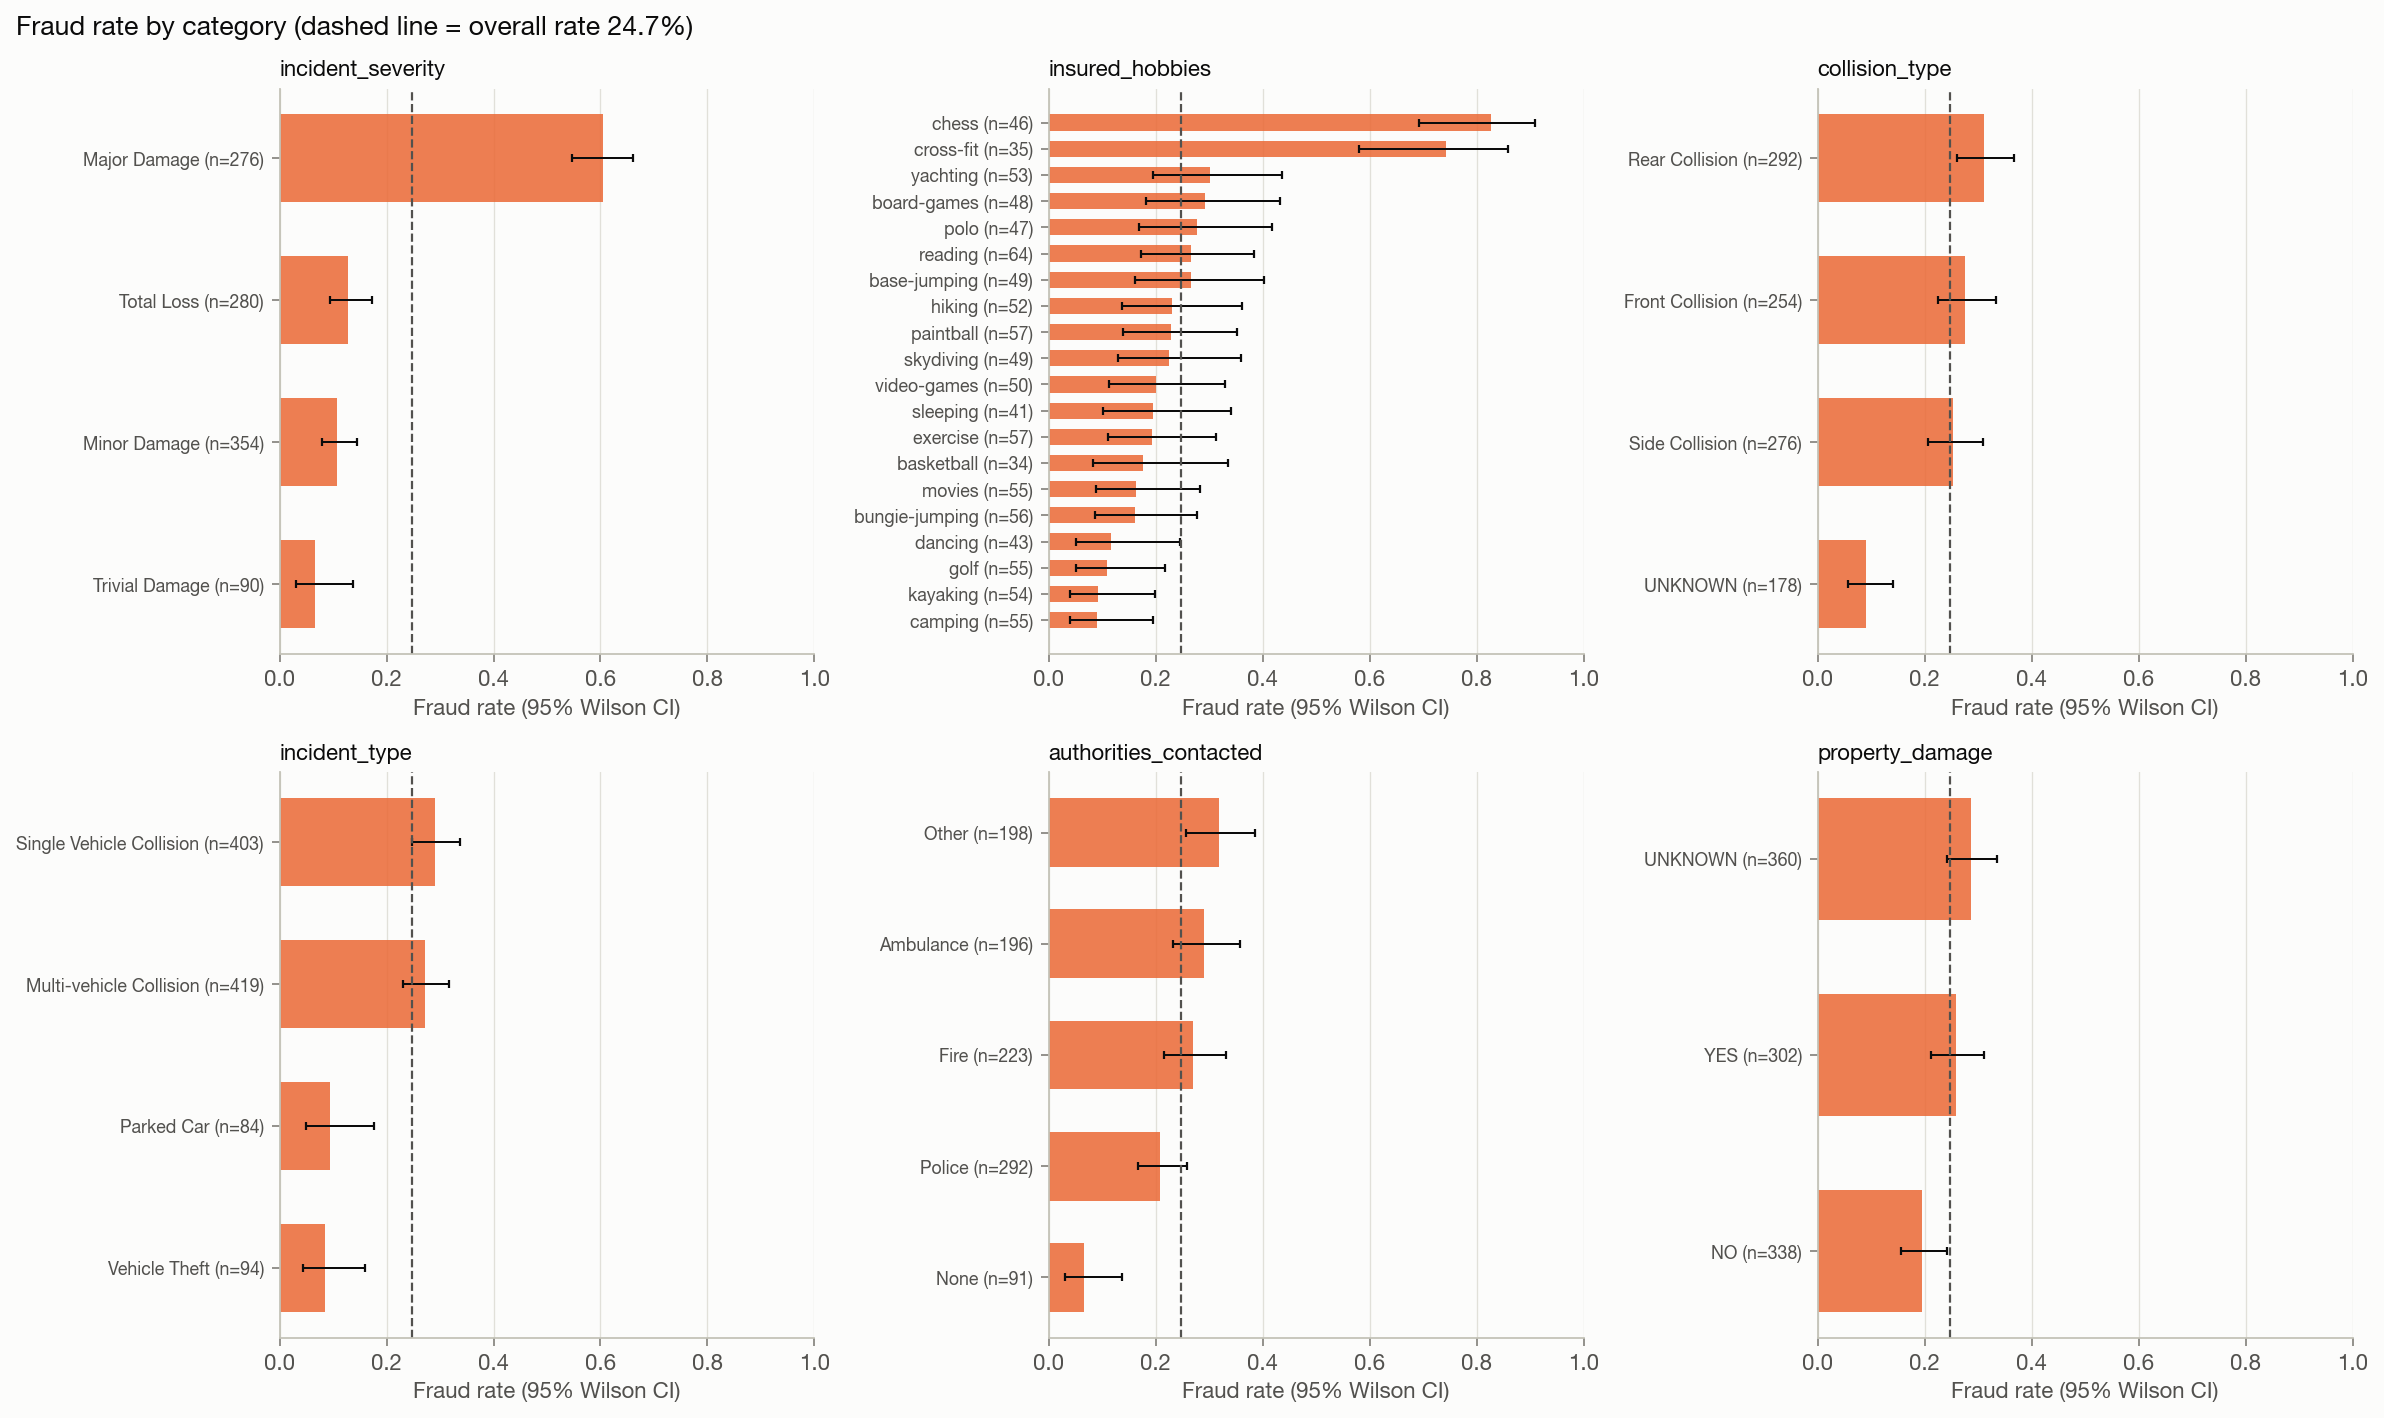

In [8]:
display(Image(FIG / 'eda_fraud_rate_by_category.png'))

Two categorical variables stand out by far:

* `incident_severity = Major Damage`: ~60 % fraud vs 7-13 % for the other levels;
* `insured_hobbies` in {chess, cross-fit}: 83 % and 74 % fraud vs ~10-30 % elsewhere.

The hobby effect has no plausible causal story and is a strong hint that this public dataset is partly simulated. It is kept (the task is to model this dataset) but its impact is quantified by an ablation and flagged in the README.

In [9]:
from src.stages.eda import fraud_rate_table
fraud_rate_table(df, 'insured_hobbies').tail(4)

,sum,count,rate,lo,hi
insured_hobbies,,,,,
board-games,14,48,0.292,0.182,0.432
yachting,16,53,0.302,0.195,0.435
cross-fit,26,35,0.743,0.579,0.858
chess,38,46,0.826,0.693,0.909


## Correlations

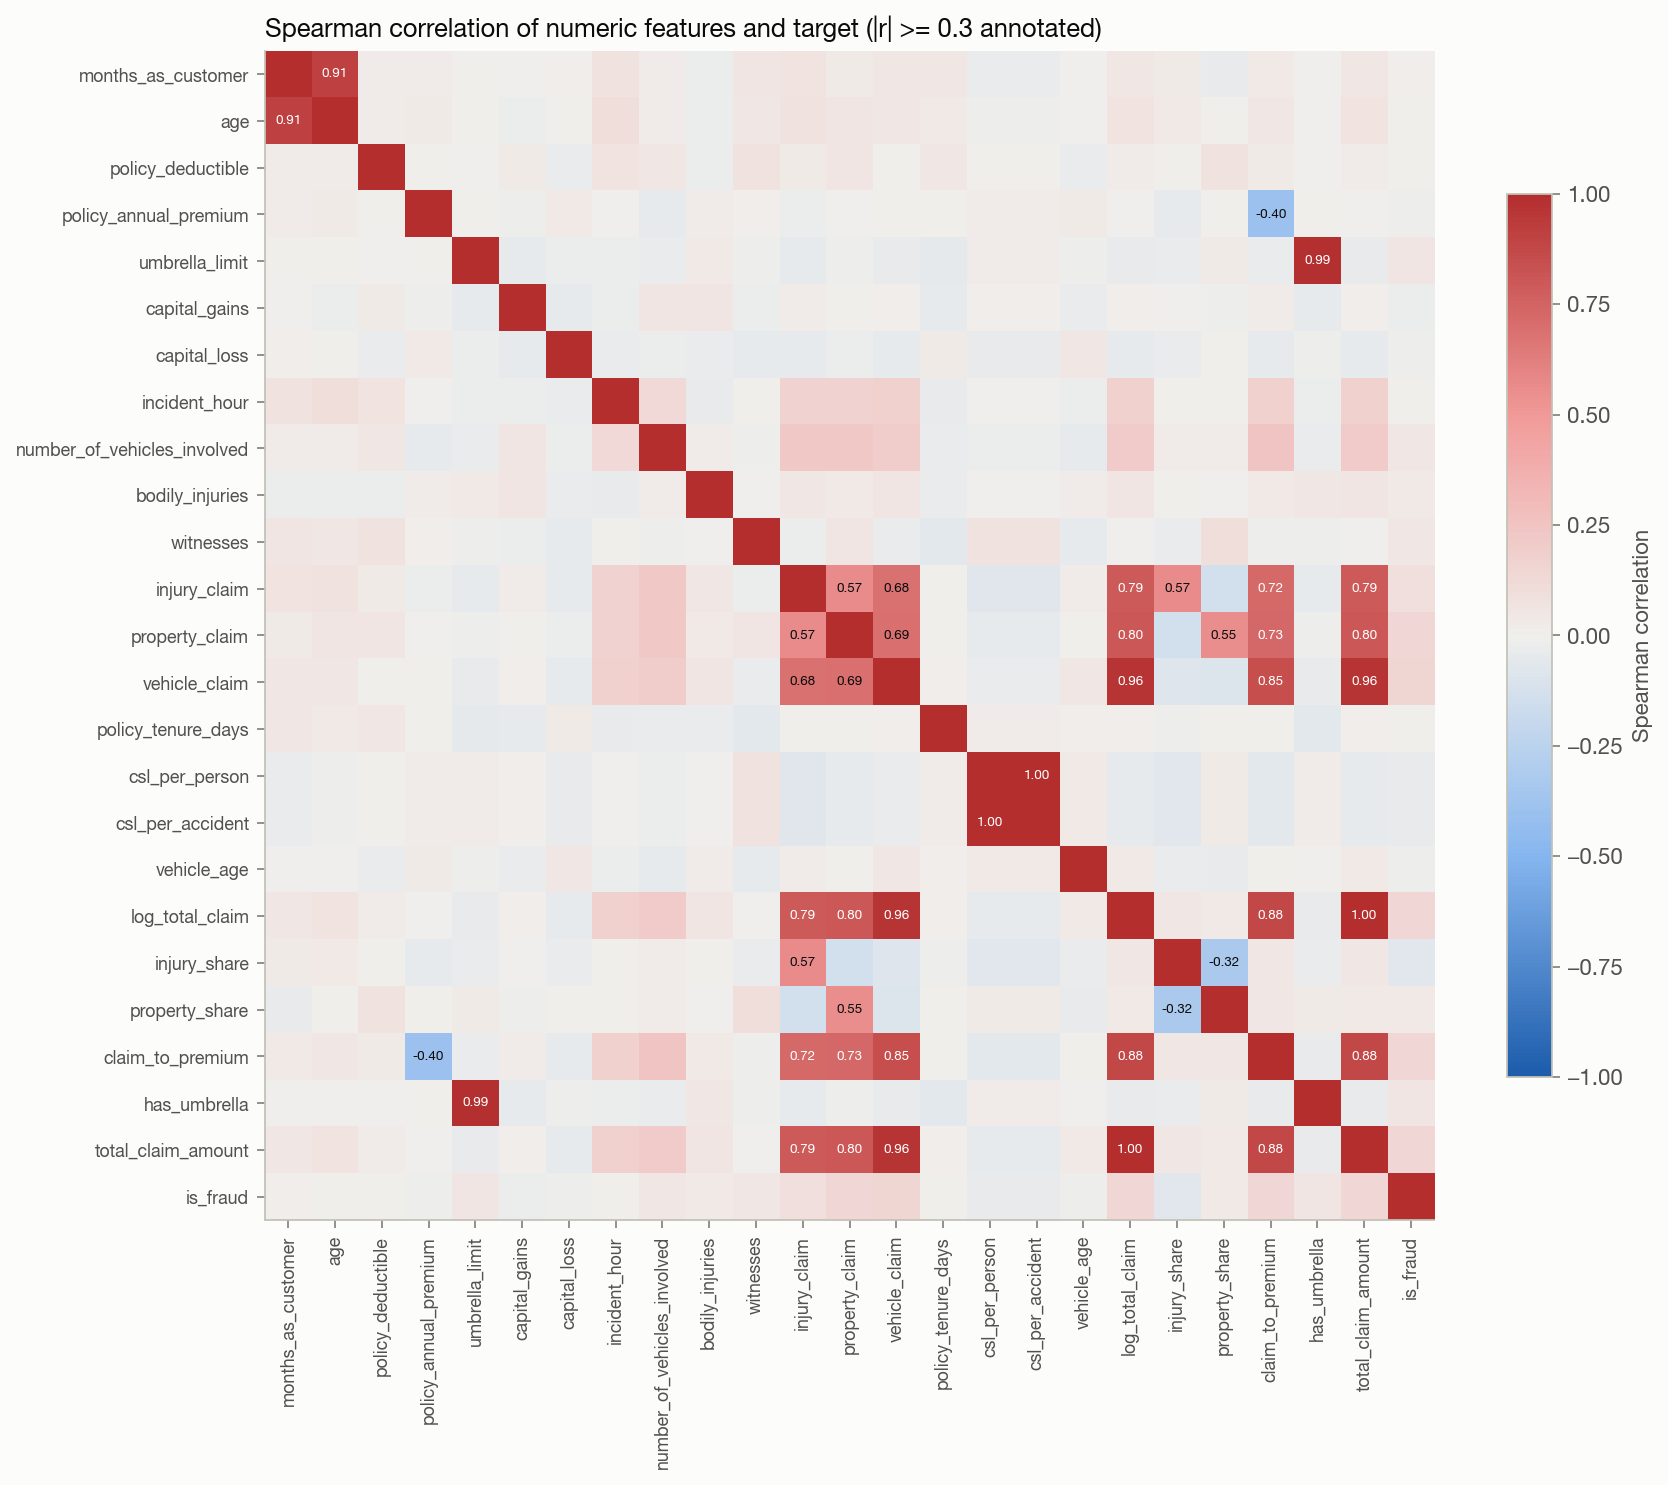

In [10]:
display(Image(FIG / 'eda_correlation_matrix.png'))

Strong correlations are confined to blocks of mechanically related variables (`age` / `months_as_customer`; the claim components and their total). Correlations with the target are weak for every numeric variable, which explains why the former 4-variable model (age, premium, umbrella limit, tenure) could not beat chance (ROC-AUC 0.50).